# Modellizzazione Monte Carlo per Frange di Interferenza e Diffrazione

### Scopo della prova
Lo scopo di questa prova è costruire un esperimento virtuale partendo da un modello teorico di intensità luminosa.<br> Verrà simulata prima una singola acquisizione, per poi ripetere l'esperimento N volte al fine di studiare la distribuzione statistica di uno stimatore, distinguendo tra la curva attesa, una realizzazione casuale e l'intera distribuzione dei risultati possibili.

### Modello fisico
Il numero medio atteso di conteggi nel punto $x$ è:

$$\mu(x) = B + I_0 \left[ \frac{\sin(\alpha x)}{\alpha x} \right]^2 \cos^2(\delta x)$$

Dove i parametri iniziali sono:
*   **$B$**: Fondo uniforme $B$, posto pari a 20 conteggi per bin.
*   **$I_0$**: Scala del segnale $I_{0}$, posta a 400 conteggi per bin.
*   **$\alpha$**: Larghezza dell'inviluppo $\alpha$, pari $0.90 \, \text{mm}^{-1}$.
*   **$\delta$**: Frequenza spaziale delle frange $\delta$, posta a $5.20 \, \text{mm}^{-1}$.

Si studierà il fenomeno in un intervallo $-5.0 \, \text{mm} \le x \le 5.0 \, \text{mm}$ utilizzando $161$ punti equidistanti.



In [90]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

B = 20          # u.d.m: conteggi/bin
I = 400         # u.d.m: conteggi/bin
alpha = 0.9     # u.d.m: mm^-1
delta = 5.2     # u.d.m: mm^-1

x_min = -5
x_max = 5
N_bin = 161

x_plot = np.linspace(x_min, x_max, N_bin)

## Attività 1: Costruzione del modello

Procediamo ora a implementare la funzione $\mu(x)$ separandola in due componenti:
* $E(x) = \left[ \frac{\sin(\alpha x)}{\alpha x} \right]^2$.
* $C(x) = \cos^2(\delta x)$.

Calcoleremo e rappresenteremo graficamente $\mu(x)$, il fondo continuo $B$ e l'inviluppo superiore dato da $B + I_0 E(x)$. Successivamente, verificheremo tramite codice che la funzione sia finita, non negativa, simmetrica e che $\mu(0)$ sia compatibile con l'attesa $B+I_0$.

La funzione è non negativa:  True
La funzione è simmetrica:  True
La funzione in zero è ben definita:  True


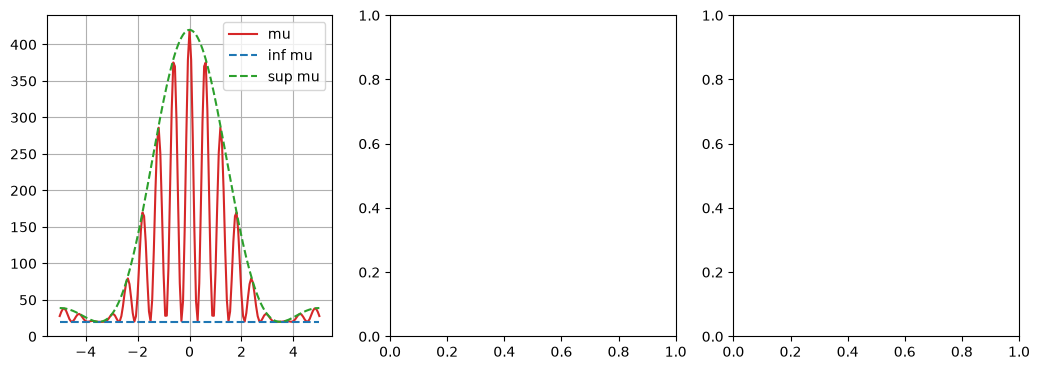

In [91]:
def E(x, alpha):
    return  np.sinc(alpha*x/np.pi)**2

def C(x, delta):
    return np.cos(delta*x)**2

def mu(x, B, I, alpha, delta):
    return B + I*E(x, alpha)*C(x, delta)

def mu_sup(x, B, I, alpha):
    return B + I*E(x, alpha)

def mu_is_positive0(x, B, I, alpha, delta):
    i = x_min
    for i in  range (x_min, x_max):
        if mu(x, B, I, alpha, delta)[i] < 0:
            return False
        i += abs(x_max - x_min)/N_bin
    return True

def mu_is_simmetric(x, B, I, alpha, delta):
    i = x_min
    for i in  range (x_min, 0):
        if abs(mu(x, B, I, alpha, delta)[i] - mu(x, B, I, alpha, delta)[-i]) >= 10:
            return False
        i += abs(x_max - x_min)/N_bin
    return True

def mu_in_0(x, B, I, alpha, delta): 
    i = x_min
    for i in  range (x_min, x_max):
            if B + I != mu(x, B, I, alpha, delta)[i]:
                return False
            i += abs(x_max - x_min)/N_bin
    return True


mu_plot = mu(x_plot, B, I, alpha, delta)
mu_sup_plot = mu_sup(x_plot, B, I, alpha)
B_plot = np.full(N_bin, B)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8))
axes[0].plot(x_plot, mu_plot, color="tab:red", label="mu")
axes[0].plot(x_plot, B_plot, color="tab:blue", linestyle="--", label="inf mu")
axes[0].plot(x_plot, mu_sup_plot, color="tab:green", linestyle="--", label="sup mu")
axes[0].grid(True)
axes[0].legend()

print("La funzione è non negativa: ", mu_is_positive0(x_plot, B, I, alpha, delta))
print("La funzione è simmetrica: ",mu_is_simmetric(x_plot, B, I, alpha, delta))
print("La funzione in zero è ben definita: ", mu_in_0(np.full(N_bin, 0), B, I, alpha, delta))

plt.tight_layout()
plt.show()

## Attività 2: Simulazione di un'acquisizione

In questa fase simuleremo una singola acquisizione sperimentale. Per ogni posizione $x_i$, genereremo un numero di conteggi casuale indipendente estratto da una distribuzione di **Poisson**:
$$ n_i \sim \text{Poisson}(\mu_i), \quad \mu_i = \mu(x_i) $$

Successivamente, calcoleremo i conteggi totali registrati nella regione  centrale <br>$|x_i| < 1.2 \, \text{mm}$ e li confronteremo con il valore teorico atteso per la medesima regione:
*   Conteggi simulati: $N_c = \sum_{|x_i|<1.2} n_i$
*   Conteggi attesi: $\mu_c = \sum_{|x_i|<1.2} \mu_i$

Valuteremo infine se la discrepanza osservata ($N_c - \mu_c$) è compatibile con le fluttuazioni statistiche (quantificate da $\sqrt{\mu_c}$).

Compatibilità tra mu_c e N_c entro un sigma_N_c (prima simulazione):  True


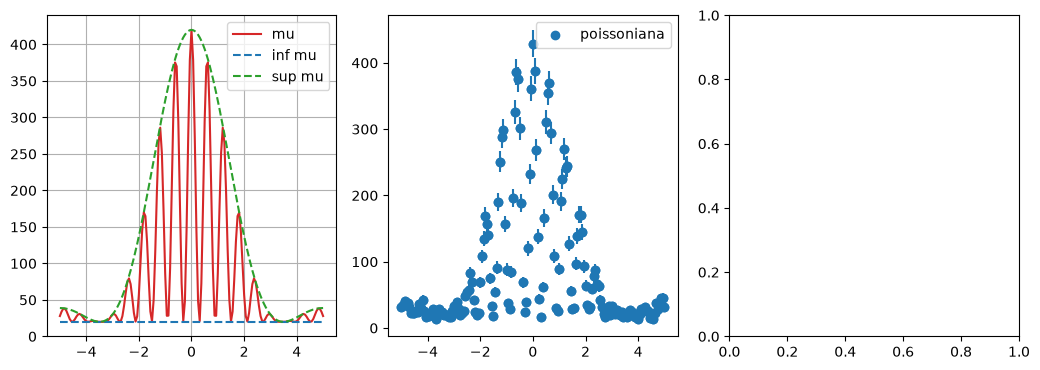

In [92]:
def sum_n_i(n_i, x):
    sum = 0
    i = 0
    for x_i in  x:
        if abs(x_i)< 1.2:
            sum += n_i[i]
        i += 1
    return sum

def compare_with_error (res, error):
    return abs(res)<error


rng = np.random.default_rng(18032006)

n_i = rng.poisson(lam=mu_plot, size=N_bin)
n_i_err = np.sqrt(n_i)
mu_c = sum_n_i(mu(x_plot, B, I, alpha, delta), x_plot)
res = sum_n_i(n_i, x_plot) - mu_c
sigma_N_c = np.sqrt(mu_c)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8))
axes[0].plot(x_plot, mu_plot, color="tab:red", label="mu")
axes[0].plot(x_plot, B_plot, color="tab:blue", linestyle="--", label="inf mu")
axes[0].plot(x_plot, mu_sup_plot, color="tab:green", linestyle="--", label="sup mu")
axes[0].grid(True)
axes[0].legend()

axes[1].scatter(x_plot, n_i, color="tab:blue", label="poissoniana")
axes[1].errorbar(x_plot, n_i, n_i_err, fmt='o', color="tab:blue")
axes[1].legend()

print("Compatibilità tra mu_c e N_c entro un sigma_N_c (prima simulazione): ", compare_with_error (res, sigma_N_c))

plt.tight_layout()
plt.show()

## Attività 3: Distribuzione dello stimatore

Adesso ripeteremo l'acquisizione 2000 volte.

Per ogni $j$-esimo esperimento, calcoleremo nuovamente:
$$ N_c^{(j)} = \sum_{|x_i|<1.2} n_i^{(j)} $$

e mettero tutti i risultati all'interno di una matrice tale per cui quest'utlima avrà sulle righe i conteggi del j-esimo esperimento e sulle colonne i conteggi relativi ad ogni $x$.

Studieremo quindi la distribuzione dei $2000$ valori di $N_c$ ottenuti, calcolando:
*   La media delle simulazioni, *N_c_mean*.
*   La deviazione standard campionaria (con $\text{dof}=1$), *N_c_std*.
*   L'errore standard sulla media, *N_c_mean_std*.
*   Lo scarto relativo rispetto al valore atteso $\mu_c$ calcolato in precedenza, *res_mu*.

CONFRONTARE DEV STANDARD (non compatibilità)...

Media della distribuzione di N_c:  7648.479
Deviazione standard della distribuzione di N_c:  86.46856055805769
Deviazione della media della distribuzione di N_c:  1.9334957932437413
Compatibilità tra mu_c e N_c_mean entro un sigma_N_c:  True


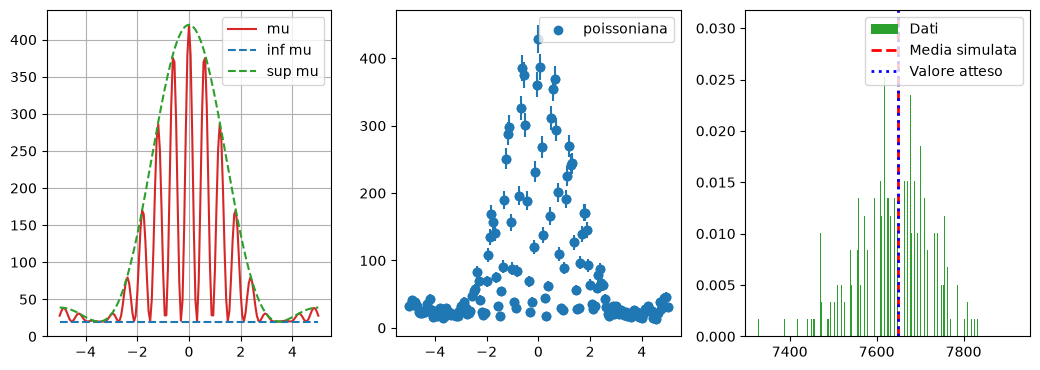

In [94]:
def N_experiments_matrix(N_, N_bin, x, B, I, alpha, delta):
    A = None
    for i in range (N_):
        rng = np.random.default_rng(i)
        y_plot =  rng.poisson(lam=mu(x, B, I, alpha, delta), size=N_bin)
        if A is None:
            A = y_plot
        else:
            A = np.column_stack((A, y_plot))
    return A.T


def sum_n_i_experiments(A, N_, x):
    N_c = np.empty(N_)
    for i in range (N_):
        N_c[i] = sum_n_i(A[i], x)
    return N_c

N_experiments = 2000

A = N_experiments_matrix(N_experiments, N_bin, x_plot, B, I, alpha, delta, )
N_c = sum_n_i_experiments(A, N_experiments, x_plot)
N_c_mean = np.mean(N_c)
N_c_std = np.std(N_c, ddof=1)
N_c_mean_std = np.std(N_c, ddof=1)/np.sqrt(len(N_c))
res_mu = N_c_mean - mu_c

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8))
axes[0].plot(x_plot, mu_plot, color="tab:red", label="mu")
axes[0].plot(x_plot, B_plot, color="tab:blue", linestyle="--", label="inf mu")
axes[0].plot(x_plot, mu_sup_plot, color="tab:green", linestyle="--", label="sup mu")
axes[0].grid(True)
axes[0].legend()

axes[1].scatter(x_plot, n_i, color="tab:blue", label="poissoniana")
axes[1].errorbar(x_plot, n_i, n_i_err, fmt='o', color="tab:blue")
axes[1].legend()

axes[2].hist(N_c, N_experiments, density=True, color="tab:green", label="Dati")
axes[2].axvline(N_c_mean, color="red", linestyle="--", linewidth=2, label="Media simulata")
axes[2].axvline(N_c_mean, color="blue", linestyle=":", linewidth=2, label="Valore atteso")
axes[2].legend()

print ("Media della distribuzione di N_c: ", N_c_mean)
print ("Deviazione standard della distribuzione di N_c: ", N_c_std)
print ("Deviazione della media della distribuzione di N_c: ", N_c_mean_std)
print("Compatibilità tra mu_c e N_c_mean entro un sigma_N_c: ", compare_with_error (res_mu, sigma_N_c))

plt.tight_layout()
plt.show()